<a href="https://colab.research.google.com/github/DanielMerdov/winter-school-Data-Science-Danylo-Merdov-Ieva-Vai-aityt-/blob/main/sutvarkytas_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  1 Importing libraries

In [ ]:
# 1. Standard Data Processing & Math
import io
import numpy as np
import pandas as pd
from scipy import stats

# 2. Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Google Colab Utilities
from google.colab import files

# 4. Statistical Tests & Regression
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest

# 5. Machine Learning Models & Metrics (scikit-learn)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

print("All required libraries imported successfully!")

print("Libraries loaded.")

All required libraries imported successfully!
Libraries loaded.


# 2 Data loading

In [ ]:
from google.colab import files

# Upload CSV file
uploaded = files.upload()

# Load dataset
df = pd.read_csv("diabetes_prediction_dataset.csv")

# Display first 5 rows
print("--- First 5 Rows of the Dataset ---")
display(df.head())

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv
--- First 5 Rows of the Dataset ---


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


# 3 Data Overview & Missing Values Check

In [ ]:
# Check column data types and structural info
print("--- Dataset Information & Data Types ---")
print(df.info())

# Check for missing values (NaN/Null)
print("\n--- Missing Values Count per Column ---")
print(df.isnull().sum())

--- Dataset Information & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None

--- Missing Values Count per Column ---
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_

# 4 Filtering Adult Population (Age $\ge$ 18)

In [ ]:
# 1. Count records before filtering
total_before_age_filter = len(df)
minors_count = len(df[df['age'] < 18])

print("--- Age Filtering Summary ---")
print(f"Total rows before age filtering: {total_before_age_filter:,}")
print(f"Number of minor records (age < 18) to remove: {minors_count:,}")
print(
    f"Percentage of minor records: {(minors_count / total_before_age_filter) * 100:.2f}%\n"
)

# 2. Filter dataset to keep only adults (age >= 18)
df_adults = df[df['age'] >= 18].copy()

# 3. Summary after filtering
total_after_age_filter = len(df_adults)

print("--- Dataset Status After Age Filter ---")
print(f"Remaining adult records (age >= 18): {total_after_age_filter:,}")
print(f"Minimum age in filtered dataset: {df_adults['age'].min()}")
print(f"Maximum age in filtered dataset: {df_adults['age'].max()}")

--- Age Filtering Summary ---
Total rows before age filtering: 100,000
Number of minor records (age < 18) to remove: 17,219
Percentage of minor records: 17.22%

--- Dataset Status After Age Filter ---
Remaining adult records (age >= 18): 82,781
Minimum age in filtered dataset: 18.0
Maximum age in filtered dataset: 80.0


In [ ]:
# Reassign filtered adult dataset to the main 'df' variable
df = df_adults.copy()

print("--- Main Dataframe Updated ---")
print(
    f" 'df' now contains only adult records (age >= 18)."
)
print(f" Current dataset shape: {df.shape[0]:,} rows and {df.shape[1]} columns.")

--- Main Dataframe Updated ---
 'df' now contains only adult records (age >= 18).
 Current dataset shape: 82,781 rows and 9 columns.


# 5 Dublicates detection and cleaning

In [ ]:
# 1. Count duplicates before cleaning
initial_adult_rows = len(df)
duplicate_count = df.duplicated().sum()

print("--- Duplicate Summary (Adult Dataset) ---")
print(f"Total rows in adult dataset: {initial_adult_rows:,}")
print(f"Number of duplicate rows found: {duplicate_count:,}")
print(f"Percentage of duplicates: {(duplicate_count / initial_adult_rows) * 100:.2f}%\n")

# 2. Display sample duplicate rows if present
if duplicate_count > 0:
    print("--- First 10 Duplicate Rows (Sample) ---")
    duplicate_samples = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))
    display(duplicate_samples.head(10))

# 3. Drop duplicate rows and update main dataframe 'df'
df = df.drop_duplicates().copy()

# 4. Summary after cleaning
final_adult_rows = len(df)
removed_rows = initial_adult_rows - final_adult_rows

print("\n--- Summary After Removing Duplicates ---")
print(f"Rows before duplicate removal: {initial_adult_rows:,}")
print(f"Rows removed: {removed_rows:,}")
print(f"Final clean dataset size ('df'): {final_adult_rows:,}")

--- Duplicate Summary (Adult Dataset) ---
Total rows in adult dataset: 82,781
Number of duplicate rows found: 3,323
Percentage of duplicates: 4.01%

--- First 10 Duplicate Rows (Sample) ---


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
39832,Female,18.0,0,0,No Info,27.32,3.5,130,0
88886,Female,18.0,0,0,No Info,27.32,3.5,130,0
17645,Female,18.0,0,0,No Info,27.32,3.5,140,0
31249,Female,18.0,0,0,No Info,27.32,3.5,140,0
36727,Female,18.0,0,0,No Info,27.32,3.5,155,0
54676,Female,18.0,0,0,No Info,27.32,3.5,155,0
44893,Female,18.0,0,0,No Info,27.32,3.5,200,0
54299,Female,18.0,0,0,No Info,27.32,3.5,200,0
84691,Female,18.0,0,0,No Info,27.32,3.5,200,0
3212,Female,18.0,0,0,No Info,27.32,4.0,155,0



--- Summary After Removing Duplicates ---
Rows before duplicate removal: 82,781
Rows removed: 3,323
Final clean dataset size ('df'): 79,458


# 6 Remowing 'Other' gender

In [ ]:
# 1. Inspect current gender counts
print("--- Gender Distribution Before Cleaning ---")
print(df['gender'].value_counts())
print("\nPercentage distribution:")
print(df['gender'].value_counts(normalize=True) * 100)

# 2. Count 'Other' records
other_count = (df['gender'] == 'Other').sum()
rows_before_gender_cleaning = len(df)

print(f"\nNumber of 'Other' gender records to remove: {other_count}")

# 3. Filter out 'Other' gender records and update main dataframe 'df'
df = df[df['gender'] != 'Other'].copy()

# 4. Summary after cleaning
rows_after_gender_cleaning = len(df)

print("\n--- Summary After Removing 'Other' Gender ---")
print(f"Rows before removal: {rows_before_gender_cleaning:,}")
print(f"Rows removed: {other_count}")
print(
    f"Final dataset size ('df'): {rows_after_gender_cleaning:,} rows and"
    f" {df.shape[1]} columns.\n"
)

# 5. Verify cleaned gender counts
print("--- Final Gender Distribution ---")
print(df['gender'].value_counts())

--- Gender Distribution Before Cleaning ---
gender
Female    47970
Male      31474
Other        14
Name: count, dtype: int64

Percentage distribution:
gender
Female    60.371517
Male      39.610864
Other      0.017619
Name: proportion, dtype: float64

Number of 'Other' gender records to remove: 14

--- Summary After Removing 'Other' Gender ---
Rows before removal: 79,458
Rows removed: 14
Final dataset size ('df'): 79,444 rows and 9 columns.

--- Final Gender Distribution ---
gender
Female    47970
Male      31474
Name: count, dtype: int64


# 7 Data Inspection and Missing Values Verification

In [ ]:
# 1. Summary of dataset shape and memory usage
print("--- Cleaned Dataset Overview ---")
print(f"Total rows: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")
print("\n--- Column Data Types ---")
print(df.dtypes)

# 2. Check for missing values in the cleaned dataframe
print("\n--- Missing Values Check ---")
missing_summary = df.isnull().sum()
print(missing_summary)

if missing_summary.sum() == 0:
  print(
      "\n No missing values detected in the current dataset. Imputation is"
      " not required."
  )

--- Cleaned Dataset Overview ---
Total rows: 79,444
Total columns: 9

--- Column Data Types ---
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

--- Missing Values Check ---
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

 No missing values detected in the current dataset. Imputation is not required.


# 8 Feature Engineering
Prieš užkoduojant kategorinius kintamuosius, sukursime klinikinėje praktikoje ir diabeto rizikos analizėje itin naudingus naujus kintamuosius:

bmi_category: KMI skirstymas į kategorijas (Underweight, Normal, Overweight, Obese) pagal PSO rekomendacijas.

glucose_hba1c_risk: Kombinuotas rizikos rodiklis, kai abu rodikliai (gliukozė ir HbA1c) viršija ikidiabetines ar diabetines ribas.

In [ ]:
# 1. Create BMI Category feature based on WHO standards
bmi_conditions = [
    (df['bmi'] < 18.5),
    (df['bmi'] >= 18.5) & (df['bmi'] < 25.0),
    (df['bmi'] >= 25.0) & (df['bmi'] < 30.0),
    (df['bmi'] >= 30.0)
]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese']

df['bmi_category'] = np.select(bmi_conditions, bmi_labels, default='Unknown')

# 2. Create High Risk Combo feature (Glucose >= 126 AND HbA1c >= 6.5)
df['high_risk_combo'] = np.where(
    (df['blood_glucose_level'] >= 126) & (df['HbA1c_level'] >= 6.5), 1, 0
)

print("--- Newly Created Features Summary ---")
print("BMI Category distribution:")
print(df['bmi_category'].value_counts())
print("\nHigh Risk Combo distribution (1 = High Risk, 0 = Normal/Elevated):")
print(df['high_risk_combo'].value_counts())

--- Newly Created Features Summary ---
BMI Category distribution:
bmi_category
Overweight     38209
Obese          22815
Normal         17402
Underweight     1018
Name: count, dtype: int64

High Risk Combo distribution (1 = High Risk, 0 = Normal/Elevated):
high_risk_combo
0    66060
1    13384
Name: count, dtype: int64


# 9 Categorical Variable Encoding
Dabar atliksime kategorinių kintamųjų perkodavimą į skaitinį formatą (One-Hot Encoding bei Binary Encoding), kad modeliai galėtų su jais dirbti.

In [ ]:
from sklearn.preprocessing import LabelEncoder


# 2. Encoding for 'smoking_history', 'gander' and 'bmi_category'
le = LabelEncoder()
df['gender_encoded'] = le.fit_transform(df['gender'])
df['smoking_history_encoded'] = le.fit_transform(df['smoking_history'])
bmi_mapping = {'Underweight': 0, 'Normal': 1, 'Overweight': 2, 'Obese': 3}
df['bmi_category_encoded'] = df['bmi_category'].map(bmi_mapping)
df_encoded = df.copy()

print("\nNew columns list:")
print(df.columns.tolist())

display(df)
display(df.info())


New columns list:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes', 'bmi_category', 'high_risk_combo', 'gender_encoded', 'smoking_history_encoded', 'bmi_category_encoded']


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,bmi_category,high_risk_combo,gender_encoded,smoking_history_encoded,bmi_category_encoded
0,Female,80.0,0,1,never,25.19,6.6,140,0,Overweight,1,0,4,2
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,Overweight,0,0,0,2
2,Male,28.0,0,0,never,27.32,5.7,158,0,Overweight,0,1,4,2
3,Female,36.0,0,0,current,23.45,5.0,155,0,Normal,0,0,1,1
4,Male,76.0,1,1,current,20.14,4.8,155,0,Normal,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99993,Female,40.0,0,0,never,40.69,3.5,155,0,Obese,0,0,4,3
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0,Normal,0,0,0,1
99997,Male,66.0,0,0,former,27.83,5.7,155,0,Overweight,0,1,3,2
99998,Female,24.0,0,0,never,35.42,4.0,100,0,Obese,0,0,4,3


<class 'pandas.core.frame.DataFrame'>
Index: 79444 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   gender                   79444 non-null  object 
 1   age                      79444 non-null  float64
 2   hypertension             79444 non-null  int64  
 3   heart_disease            79444 non-null  int64  
 4   smoking_history          79444 non-null  object 
 5   bmi                      79444 non-null  float64
 6   HbA1c_level              79444 non-null  float64
 7   blood_glucose_level      79444 non-null  int64  
 8   diabetes                 79444 non-null  int64  
 9   bmi_category             79444 non-null  object 
 10  high_risk_combo          79444 non-null  int64  
 11  gender_encoded           79444 non-null  int64  
 12  smoking_history_encoded  79444 non-null  int64  
 13  bmi_category_encoded     79444 non-null  int64  
dtypes: float64(3), int64(8), ob

None

# 10 Setting Main Encoded Dataframe
Išsaugome užkoduotą rinkinį kaip pagrindinį tolesniems modeliavimo žingsniams:

In [ ]:
# Keep non-encoded df for EDA visualizations and df_encoded for modeling
print("Encoding successfully applied.")
print("Note: 'df' will be used for human-readable EDA charts, and 'df_encoded' for statistical models & machine learning.")

Encoding successfully applied.
Note: 'df' will be used for human-readable EDA charts, and 'df_encoded' for statistical models & machine learning.


# 11 Outlier Detection and Analysis

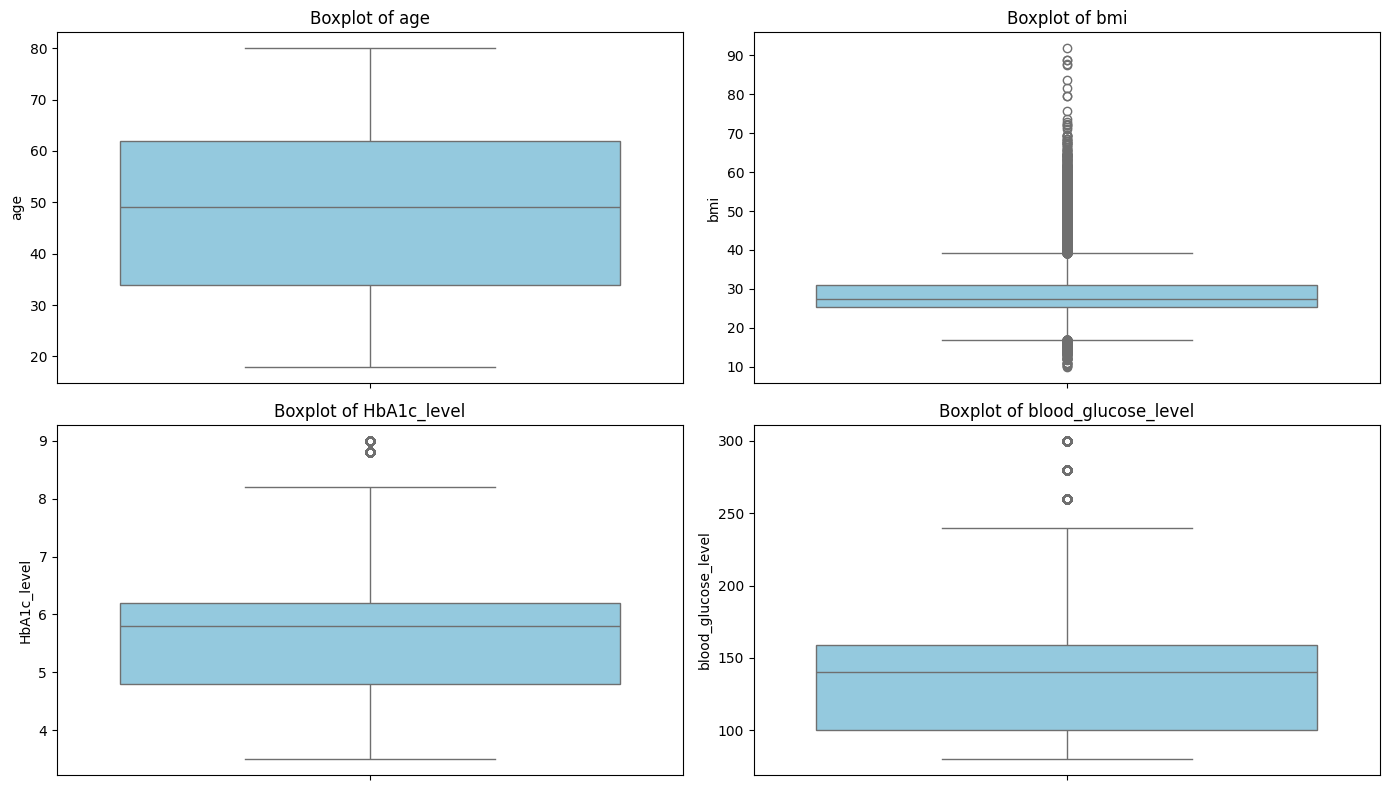

--- Outlier Identification via Interquartile Range (IQR) ---

Feature: age
  IQR: 28.00 (Q1=34.00, Q3=62.00)
  Lower Bound: -8.00, Upper Bound: 104.00
  Outliers count: 0 (0.00% of adult dataset)

Feature: bmi
  IQR: 5.58 (Q1=25.34, Q3=30.92)
  Lower Bound: 16.97, Upper Bound: 39.29
  Outliers count: 5,364 (6.75% of adult dataset)

Feature: HbA1c_level
  IQR: 1.40 (Q1=4.80, Q3=6.20)
  Lower Bound: 2.70, Upper Bound: 8.30
  Outliers count: 1,300 (1.64% of adult dataset)

Feature: blood_glucose_level
  IQR: 59.00 (Q1=100.00, Q3=159.00)
  Lower Bound: 11.50, Upper Bound: 247.50
  Outliers count: 2,008 (2.53% of adult dataset)


In [ ]:
# 1. Define key numerical features
num_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# 2. Visualize outliers using Boxplots
plt.figure(figsize=(14, 8))
for i, col in enumerate(num_features, 1):
  plt.subplot(2, 2, i)
  sns.boxplot(y=df[col], color='skyblue')
  plt.title(f'Boxplot of {col}', fontsize=12)
  plt.ylabel(col)

plt.tight_layout()
plt.show()

# 3. Calculate Outlier Statistics using Interquartile Range (IQR) Method
print("--- Outlier Identification via Interquartile Range (IQR) ---")
for col in num_features:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
  outlier_pct = (len(outliers) / len(df)) * 100

  print(f"\nFeature: {col}")
  print(f"  IQR: {IQR:.2f} (Q1={Q1:.2f}, Q3={Q3:.2f})")
  print(f"  Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
  print(
      f"  Outliers count: {len(outliers):,} ({outlier_pct:.2f}% of adult dataset)"
  )

# 12 Decision on Outlier Handling Strategy

In [ ]:
# Strategy Documentation for Report:
# 1. 'bmi', 'HbA1c_level', and 'blood_glucose_level' contain physiological outliers.
# 2. Since these high values directly represent severe diabetes and extreme obesity,
#    removing them would eliminate critical positive diabetes cases.
# 3. Decision: Retain valid clinical extreme values for tree-based algorithms and classification,
#    and apply Robust Scaling or Tree-based models that are naturally robust to outliers.

print("--- Outlier Handling Strategy Summary ---")
print(" Biologically impossible records (e.g., child with BMI 95) were eliminated via adult filtering (Age >= 18).")
print(" Remaining extreme values in BMI, Glucose, and HbA1c represent legitimate high-risk diabetic patients.")
print(" These records will be retained to preserve full medical diagnostic signal.")

--- Outlier Handling Strategy Summary ---
 Biologically impossible records (e.g., child with BMI 95) were eliminated via adult filtering (Age >= 18).
 Remaining extreme values in BMI, Glucose, and HbA1c represent legitimate high-risk diabetic patients.
 These records will be retained to preserve full medical diagnostic signal.


# 13 Exploratory Data Analysis (EDA)

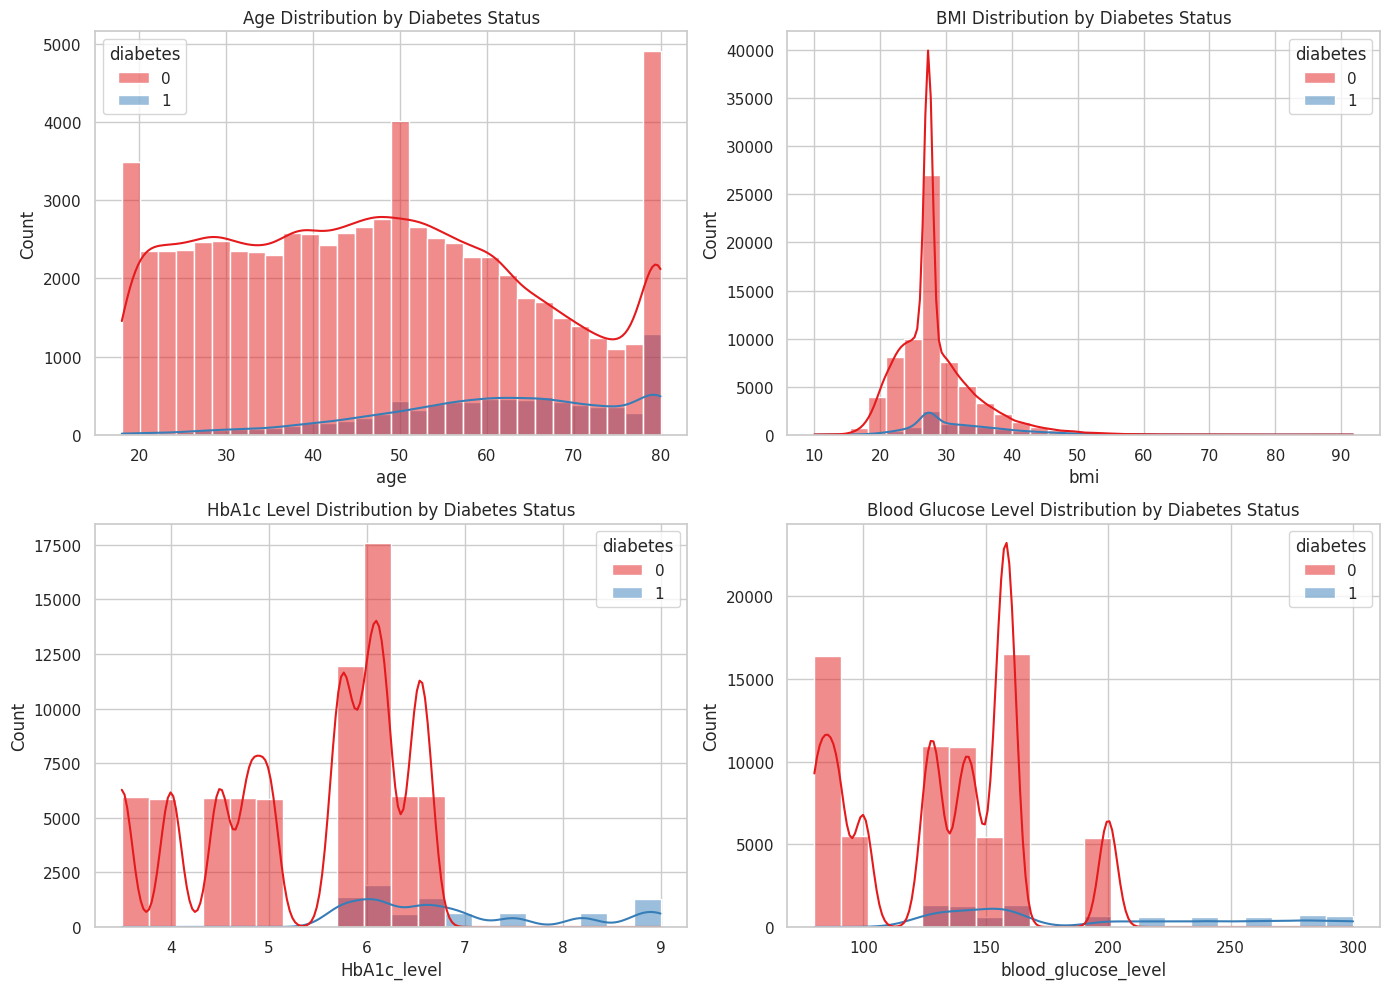

In [ ]:


# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# 1. Distribution of Key Numerical Features by Diabetes Status
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Age vs Diabetes
sns.histplot(
    data=df,
    x='age',
    hue='diabetes',
    kde=True,
    ax=axes[0, 0],
    palette='Set1',
    bins=30,
)
axes[0, 0].set_title('Age Distribution by Diabetes Status')

# BMI vs Diabetes
sns.histplot(
    data=df,
    x='bmi',
    hue='diabetes',
    kde=True,
    ax=axes[0, 1],
    palette='Set1',
    bins=30,
)
axes[0, 1].set_title('BMI Distribution by Diabetes Status')

# HbA1c Level vs Diabetes
sns.histplot(
    data=df,
    x='HbA1c_level',
    hue='diabetes',
    kde=True,
    ax=axes[1, 0],
    palette='Set1',
    bins=20,
)
axes[1, 0].set_title('HbA1c Level Distribution by Diabetes Status')

# Blood Glucose Level vs Diabetes
sns.histplot(
    data=df,
    x='blood_glucose_level',
    hue='diabetes',
    kde=True,
    ax=axes[1, 1],
    palette='Set1',
    bins=20,
)
axes[1, 1].set_title('Blood Glucose Level Distribution by Diabetes Status')

plt.tight_layout()
plt.show()

#14 Correlation Analysis

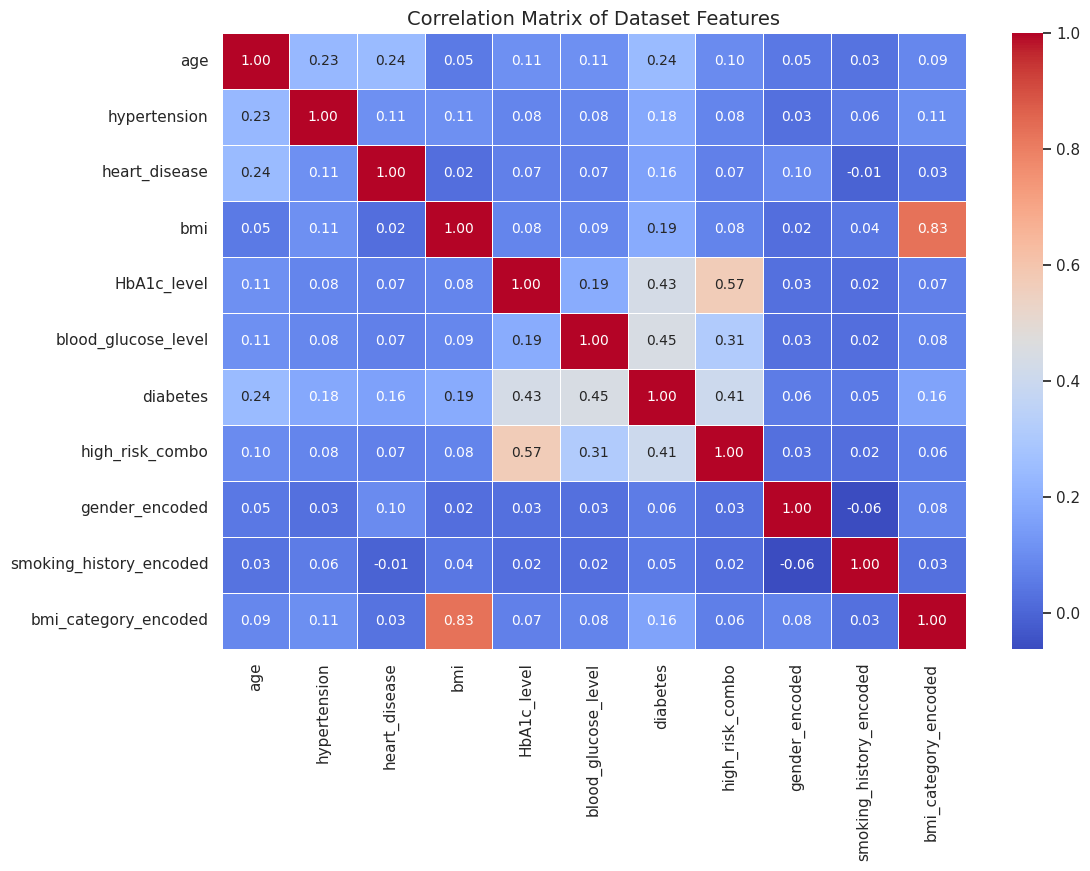

--- Correlation with Diabetes Target Variable ---
blood_glucose_level        0.447344
HbA1c_level                0.434321
high_risk_combo            0.405415
age                        0.241742
bmi                        0.189811
hypertension               0.182202
bmi_category_encoded       0.162213
heart_disease              0.161020
gender_encoded             0.056335
smoking_history_encoded    0.053728
Name: diabetes, dtype: float64


In [ ]:


# Select numerical columns from encoded dataframe for correlation
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Calculate Pearson correlation matrix
corr_matrix = df[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Dataset Features', fontsize=14)
plt.show()

# Print top correlations with Diabetes target variable
print("--- Correlation with Diabetes Target Variable ---")
diabetes_corr = (
    corr_matrix['diabetes'].sort_values(ascending=False).drop('diabetes')
)
print(diabetes_corr)

Shakiro test

#15 Hypothesis 1: One-Sample t-test (BMI vs Standard Threshold)
Formuluotė:$H_0$: Suaugusiųjų populiacijos vidutinis KMI yra lygus $25.0$ kg/m² ($\mu = 25.0$).$H_1$: Suaugusiųjų populiacijos vidutinis KMI skiriasi nuo $25.0$ kg/m² ($\mu \neq 25.0$).

In [ ]:
# 1. Shapiro-Wilk test on a sample (Shapiro-Wilk is sensitive to N > 5000, so we test normality)
stat_shapiro, p_shapiro = stats.shapiro(
    df['bmi'].sample(5000, random_state=42)
)
print(f"Shapiro-Wilk Test Statistic: {stat_shapiro:.4f}, p-value: {p_shapiro:.4e}")

# 2. Non-parametric alternative: Wilcoxon Signed-Rank Test
stat_wilc, p_wilc = stats.wilcoxon(df['bmi'] - 25.0)
print(
    f"Wilcoxon Signed-Rank Test Statistic: {stat_wilc:.4f}, p-value:"
    f" {p_wilc:.4e}"
)

Shapiro-Wilk Test Statistic: 0.8957, p-value: 6.3758e-50
Wilcoxon Signed-Rank Test Statistic: 561986116.5000, p-value: 0.0000e+00


In [ ]:
from scipy import stats

# Significance level
alpha = 0.05
pop_mean_benchmark = 25.0  # Overweight threshold

# Sample mean and size
sample_bmi = df['bmi']
sample_mean = sample_bmi.mean()
sample_std = sample_bmi.std()

# Perform One-Sample t-test
t_stat, p_val = stats.ttest_1samp(sample_bmi, pop_mean_benchmark)

print("--- Hypothesis 1: One-Sample t-test ---")
print(f"Null Hypothesis (H0): Mean BMI = {pop_mean_benchmark}")
print(f"Alternative Hypothesis (H1): Mean BMI ≠ {pop_mean_benchmark}")
print(f"Significance Level (alpha): {alpha}")
print(f"Sample Mean BMI: {sample_mean:.2f}")
print(f"Test Statistic (t-stat): {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")

# Decision rule
if p_val < alpha:
  print(
      f"\nConclusion: Reject H0 (p-value < {alpha}). The mean adult BMI"
      f" ({sample_mean:.2f}) is statistically significantly different from"
      f" {pop_mean_benchmark} kg/m²."
  )
else:
  print(
      f"\nConclusion: Fail to reject H0 (p-value >= {alpha}). There is no"
      " significant difference."
  )

--- Hypothesis 1: One-Sample t-test ---
Null Hypothesis (H0): Mean BMI = 25.0
Alternative Hypothesis (H1): Mean BMI ≠ 25.0
Significance Level (alpha): 0.05
Sample Mean BMI: 28.68
Test Statistic (t-stat): 167.7174
p-value: 0.0000e+00

Conclusion: Reject H0 (p-value < 0.05). The mean adult BMI (28.68) is statistically significantly different from 25.0 kg/m².


# 16 Hypothesis 2: Two-Sample Independent t-test (Blood Glucose by Diabetes Status)
Section 16: Hypothesis 2 — Two-Sample Independent t-testFormuluotė:
$H_0$: Sergančiųjų diabetu ir nesergančiųjų suaugusiųjų vidutinis kraujo gliukozės lygis yra vienodas ($\mu_{\text{diabetic}} = \mu_{\text{non-diabetic}}$).$H_1$: Sergančiųjų diabetu vidutinis kraujo gliukozės lygis skiriasi nuo nesergančiųjų ($\mu_{\text{diabetic}} \neq \mu_{\text{non-diabetic}}$).

In [ ]:
# Separate blood glucose values by diabetes group
glucose_diabetic = df[df['diabetes'] == 1]['blood_glucose_level']
glucose_non_diabetic = df[df['diabetes'] == 0]['blood_glucose_level']

# Perform Independent Two-Sample t-test (Welch's t-test for unequal variances)
t_stat_2sample, p_val_2sample = stats.ttest_ind(
    glucose_diabetic, glucose_non_diabetic, equal_var=False
)

print("--- Hypothesis 2: Two-Sample Independent t-test ---")
print(f"Significance Level (alpha): {alpha}")
print(f"Diabetic Mean Glucose: {glucose_diabetic.mean():.2f} mg/dL")
print(f"Non-Diabetic Mean Glucose: {glucose_non_diabetic.mean():.2f} mg/dL")
print(f"Test Statistic (t-stat): {t_stat_2sample:.4f}")
print(f"p-value: {p_val_2sample:.4e}")

# Decision rule
if p_val_2sample < alpha:
  print(
      f"\nConclusion: Reject H0 (p-value < {alpha}). There is a statistically"
      " significant difference in mean blood glucose levels between diabetic"
      " and non-diabetic adults."
  )
else:
  print(
      f"\nConclusion: Fail to reject H0 (p-value >= {alpha}). No significant"
      " difference detected."
  )

--- Hypothesis 2: Two-Sample Independent t-test ---
Significance Level (alpha): 0.05
Diabetic Mean Glucose: 193.97 mg/dL
Non-Diabetic Mean Glucose: 132.83 mg/dL
Test Statistic (t-stat): 93.7394
p-value: 0.0000e+00

Conclusion: Reject H0 (p-value < 0.05). There is a statistically significant difference in mean blood glucose levels between diabetic and non-diabetic adults.


# 17 Hypothesis 3 — Chi-Square ($\chi^2$) Test of Independence
Formuluotė:$H_0$: Lytis (gender) ir diabeto diagnozė (diabetes) yra nepriklausomi kintamieji.$H_1$: Lytis ir diabeto diagnozė yra priklausomi kintamieji (egzistuoja ryšys)

In [ ]:

# Create contingency table
contingency_table = pd.crosstab(df['gender'], df['diabetes'])

# Perform Chi-Square test
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

print("--- Hypothesis 3: Chi-Square Test of Independence ---")
print("Contingency Table (Gender vs Diabetes):")
display(contingency_table)
print(f"\nSignificance Level (alpha): {alpha}")
print(f"Degrees of Freedom (dof): {dof}")
print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"p-value: {p_val_chi2:.4e}")

# Decision rule
if p_val_chi2 < alpha:
  print(
      f"\nConclusion: Reject H0 (p-value < {alpha}). There is a statistically"
      " significant relationship between gender and diabetes diagnosis."
  )
else:
  print(
      f"\nConclusion: Fail to reject H0 (p-value >= {alpha}). Gender and"
      " diabetes appear to be independent."
  )

--- Hypothesis 3: Chi-Square Test of Independence ---
Contingency Table (Gender vs Diabetes):


diabetes,0,1
gender,,
Female,43571,4399
Male,27473,4001



Significance Level (alpha): 0.05
Degrees of Freedom (dof): 1
Chi-Square Statistic: 251.7504
p-value: 1.0786e-56

Conclusion: Reject H0 (p-value < 0.05). There is a statistically significant relationship between gender and diabetes diagnosis.


1. Pirmosios hipotezės interpretacija (One-Sample t-test)Gauti rezultatai:Imties vidurkis: $28.68$ kg/m² (lyginamas su PSO norma $\mu_0 = 25.0$ kg/m²)Testo statistika ($t$): $167.72$$p$-reikšmė: $0.0000$ ($p < 0.05$)Akademinė interpretacija: Kadangi $p$-reikšmė yra zymiai mažesnė už pasirinktą reikšmingumo lygmenį ($\alpha = 0.05$), nulinę hipotezę ($H_0$) atmetame.Praktinė / Medicininė išvada: Tyrimo imties suaugusiųjų vidutinis KMI ($28.68$ kg/m²) yra statistiškai reikšmingai didesnis už Pasaulio sveikatos organizacijos (PSO) nustatytą viršsvorio ribą ($25.0$ kg/m²). Tai rodo, kad analizuojamoje populacijoje bendras svorio vidurkis jau patenka į viršsvorio (Overweight) kategoriją ir yra arti nutukimo ribos ($30.0$ kg/m²).2. Antrosios hipotezės interpretacija (Two-Sample Independent t-test)Gauti rezultatai:Sergančiųjų diabetu vidutinė gliukozė: $193.97$ mg/dLNesergančiųjų vidutinė gliukozė: $132.83$ mg/dLTesto statistika ($t$): $93.74$$p$-reikšmė: $0.0000$ ($p < 0.05$)Akademinė interpretacija: Kadangi $p$-reikšmė ($0.0000$) yra mažesnė už $\alpha = 0.05$, nulinę hipotezę ($H_0$) atmetame.Praktinė / Medicininė išvada: Tarp sergančiųjų diabetu ir nesergančiųjų asmenų egzistuoja statistiškai itin reikšmingas kraujo gliukozės vidurkių skirtumas (vidutiniškai net $+61.14$ mg/dL didesnis sergančiųjų grupėje). Tai visiškai atitinka klinikinius diagnostikos standartus — kraujo gliukozės lygis yra vienas iš pagrindinių ir stipriausių diabeto indikatorių.3. Trečiosios hipotezės interpretacija (Chi-Square Test of Independence)Gauti rezultatai:Laisvės laipsniai ($dof$): $1$$\chi^2$ statistika: $251.75$$p$-reikšmė: $1.08 \times 10^{-56}$ ($p < 0.05$)Proporcijos iš lentelės:Moterų sergamumas: $4\,399 / (43\,571 + 4\,399) \approx \mathbf{9.17\%}$Vyro sergamumas: $4\,001 / (27\,473 + 4\,001) \approx \mathbf{12.71\%}$Akademinė interpretacija: Kadangi $p$-reikšmė ($1.08 \times 10^{-56}$) yra artima nuliui ir žymiai mažesnė už $\alpha = 0.05$, nulinę hipotezę ($H_0$) atmetame.Praktinė / Medicininė išvada: Egzistuoja statistiškai reikšmingas ryšys tarp lyties ir diabeto diagnozės. Analizuojamoje imtyje vyrai pasižymi statistiškai didesne diabeto pasireiškimo proporcija ($12.71\%$) lyginant su moterimis ($9.17\%$).

# 18 Multiple Linear Regression Analysis

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Select Target (Y) and Predictors (X) for Linear Regression
# Dependent variable: blood_glucose_level
# Independent variables: age, bmi, HbA1c_level, hypertension, heart_disease, gender_encoded
X_lin = df_encoded[[
    'age',
    'bmi',
    'HbA1c_level',
    'hypertension',
    'heart_disease',
    'gender_encoded',
]]
y_lin = df_encoded['blood_glucose_level']

# Add constant for intercept in statsmodels
X_lin_const = sm.add_constant(X_lin)

# 2. Fit Multiple Linear Regression Model using Ordinary Least Squares (OLS)
lin_model = sm.OLS(y_lin, X_lin_const).fit()

# Print statistical summary (Includes t-test for individual coefficients and F-test for overall model)
print("--- Linear Regression OLS Summary ---")
print(lin_model.summary())

# 3. Calculate Performance Metrics
y_pred_lin = lin_model.predict(X_lin_const)

mae = mean_absolute_error(y_lin, y_pred_lin)
mse = mean_squared_error(y_lin, y_pred_lin)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(y_lin, y_pred_lin) * 100
r2 = r2_score(y_lin, y_pred_lin)

print("\n--- Linear Regression Performance Metrics ---")
print(f"MAE (Mean Absolute Error): {mae:.4f}")
print(f"MSE (Mean Squared Error): {mse:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"MAPE (Mean Absolute Percentage Error): {mape:.2f}%")
print(f"R-squared (R²): {r2:.4f}")

--- Linear Regression OLS Summary ---
                             OLS Regression Results                            
Dep. Variable:     blood_glucose_level   R-squared:                       0.053
Model:                             OLS   Adj. R-squared:                  0.053
Method:                  Least Squares   F-statistic:                     740.8
Date:                 Thu, 08 Oct 2026   Prob (F-statistic):               0.00
Time:                         18:22:42   Log-Likelihood:            -4.0755e+05
No. Observations:                79444   AIC:                         8.151e+05
Df Residuals:                    79437   BIC:                         8.152e+05
Df Model:                            6                                         
Covariance Type:             nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

# 19 Linear Regression Equation and Prediction Examples

In [ ]:
# 1. Derive regression equation parameters
intercept = lin_model.params['const']
coefs = lin_model.params.drop('const')

print("--- Linear Regression Equation ---")
eq_terms = [f"{coef:.4f} * ({col})" for col, coef in coefs.items()]
print(f"blood_glucose_level = {intercept:.4f} + " + " + ".join(eq_terms))

# 2. Make prediction for a new unseen data point
# Example patient: Age 50, BMI 28.5, HbA1c 6.2, Hypertension 0, Heart Disease 0, Gender Male (1)
new_patient = pd.DataFrame([{
    'const': 1.0,
    'age': 50,
    'bmi': 28.5,
    'HbA1c_level': 6.2,
    'hypertension': 0,
    'heart_disease': 0,
    'gender_encoded': 1,
}])

predicted_glucose = lin_model.predict(new_patient)[0]

print("\n--- Prediction for New Data Point ---")
print(f"New Patient Profile: Age=50, BMI=28.5, HbA1c=6.2, Gender=Male")
print(
    f"Predicted Blood Glucose Level: {predicted_glucose:.2f} mg/dL"
)

--- Linear Regression Equation ---
blood_glucose_level = 80.3387 + 0.1630 * (age) + 0.4324 * (bmi) + 6.7065 * (HbA1c_level) + 6.0614 * (hypertension) + 6.6370 * (heart_disease) + 1.1001 * (gender_encoded)

--- Prediction for New Data Point ---
New Patient Profile: Age=50, BMI=28.5, HbA1c=6.2, Gender=Male
Predicted Blood Glucose Level: 143.49 mg/dL


# 20 Binary Logistic Regression Analysis
Dabar atliksime logistinę regresiją, kad galėtume prognozuoti diabetes diagnozę (0/1).

--- Binary Logistic Regression Coefficients ---


,Feature,Coefficient,Odds_Ratio (exp)
0,age,0.913878,2.493976
1,bmi,0.617793,1.854831
2,HbA1c_level,2.346925,10.453376
3,blood_glucose_level,1.319564,3.741791
4,hypertension,0.225008,1.252333
5,heart_disease,0.155078,1.167749
6,gender_encoded,0.168154,1.183119


Intercept: -2.3735


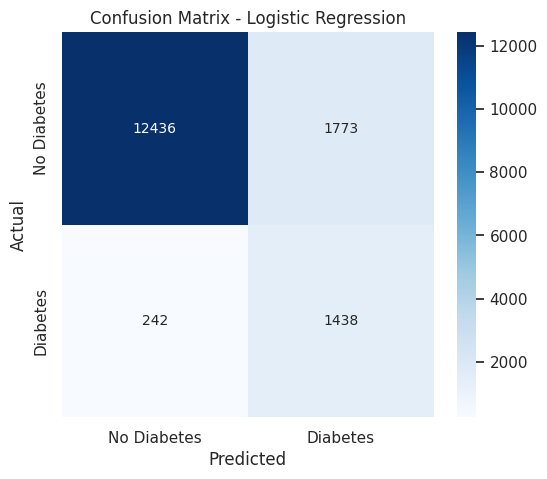

--- Binary Logistic Regression Performance Metrics ---
Accuracy: 0.8732
Precision: 0.4478
Recall: 0.8560 (Crucial for Medical Data)
F1-Score: 0.5880
ROC-AUC Score: 0.9525


In [ ]:
from sklearn.preprocessing import StandardScaler


# 1. Define X and y for Logistic Regression
X_log = df[[
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level',
    'hypertension',
    'heart_disease',
    'gender_encoded',
]]
y_log = df['diabetes']

# 2. Split dataset into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train Binary Logistic Regression Model

log_reg = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
log_reg.fit(X_train_scaled, y_train)

# Predict classes and probabilities
y_pred_log = log_reg.predict(X_test_scaled)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# 4. Display Coefficients & Odds Ratios
print("--- Binary Logistic Regression Coefficients ---")

coef_df = pd.DataFrame(
    {'Feature': X_log.columns, 'Coefficient': log_reg.coef_[0]}
)
coef_df['Odds_Ratio (exp)'] = np.exp(coef_df['Coefficient'])
display(coef_df)

print(f"Intercept: {log_reg.intercept_[0]:.4f}")

# 5. Confusion Matrix & Classification Metrics
cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes'],
)
plt.title('Confusion Matrix - Logistic Regression')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Calculate classification metrics
acc = accuracy_score(y_test, y_pred_log)
prec = precision_score(y_test, y_pred_log)
rec = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)
roc_auc = roc_auc_score(y_test, y_prob_log)

print("--- Binary Logistic Regression Performance Metrics ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall: {rec:.4f} (Crucial for Medical Data)")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")

# 21 Dataset Splitting (Train/Test) for Decision Tree

In [ ]:
from sklearn.model_selection import train_test_split

# Identify non-numeric string columns or original target column to drop safely
cols_to_drop = [
    col
    for col in ['diabetes', 'bmi_category', 'gender','smoking_history']
    if col in df.columns
]

# Define Features (X) and Target (y)
X_dt = df.drop(columns=cols_to_drop)
y_dt = df['diabetes']

# Split dataset into 80% Training and 20% Testing sets with stratification
X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(
    X_dt, y_dt, test_size=0.2, random_state=42, stratify=y_dt
)

print("--- Data Splitting Summary ---")
print(f"Training set shape: {X_train_dt.shape[0]:,} rows")
print(f"Testing set shape:  {X_test_dt.shape[0]:,} rows")
print(f"Features count:     {X_train_dt.shape[1]}")
print("\nFeatures used for Decision Tree:")
print(X_dt.columns.tolist())

--- Data Splitting Summary ---
Training set shape: 63,555 rows
Testing set shape:  15,889 rows
Features count:     10

Features used for Decision Tree:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'high_risk_combo', 'gender_encoded', 'smoking_history_encoded', 'bmi_category_encoded']


# 22 Evaluating Classification Performance across Varying Tree Depths

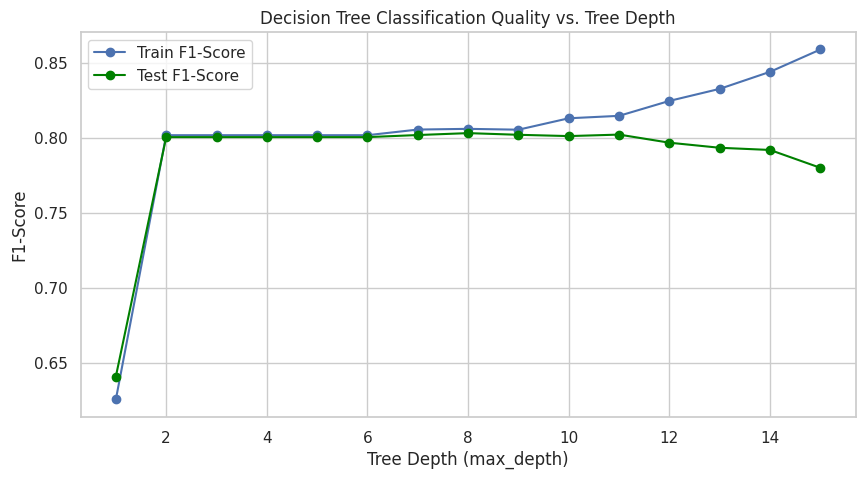

 Best classification performance achieved at max_depth = 8 (Test F1-Score: 0.8031)


In [ ]:

# Test varying max_depth values from 1 to 15
depths = range(1, 16)
train_f1_scores = []
test_f1_scores = []

text_columns = ['gender', 'smoking_history', 'bmi_category']

X_train_dt = X_train_dt.drop(columns=text_columns, errors='ignore')
X_test_dt = X_test_dt.drop(columns=text_columns, errors='ignore')

for depth in depths:
  clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
  clf.fit(X_train_dt, y_train_dt)

  y_pred_train = clf.predict(X_train_dt)
  y_pred_test = clf.predict(X_test_dt)

  train_f1_scores.append(f1_score(y_train_dt, y_pred_train))
  test_f1_scores.append(f1_score(y_test_dt, y_pred_test))

# Plot performance curve
plt.figure(figsize=(10, 5))
plt.plot(depths, train_f1_scores, label='Train F1-Score', marker='o')
plt.plot(
    depths, test_f1_scores, label='Test F1-Score', marker='o', color='green'
)
plt.xlabel('Tree Depth (max_depth)')
plt.ylabel('F1-Score')
plt.title('Decision Tree Classification Quality vs. Tree Depth')
plt.legend()
plt.grid(True)
plt.show()

# Find best depth based on Test F1-Score
best_depth = depths[test_f1_scores.index(max(test_f1_scores))]
print(
    f" Best classification performance achieved at max_depth ="
    f" {best_depth} (Test F1-Score: {max(test_f1_scores):.4f})"
)

# 23 Evaluating Classification Performance with Varying Min Leaf Samples

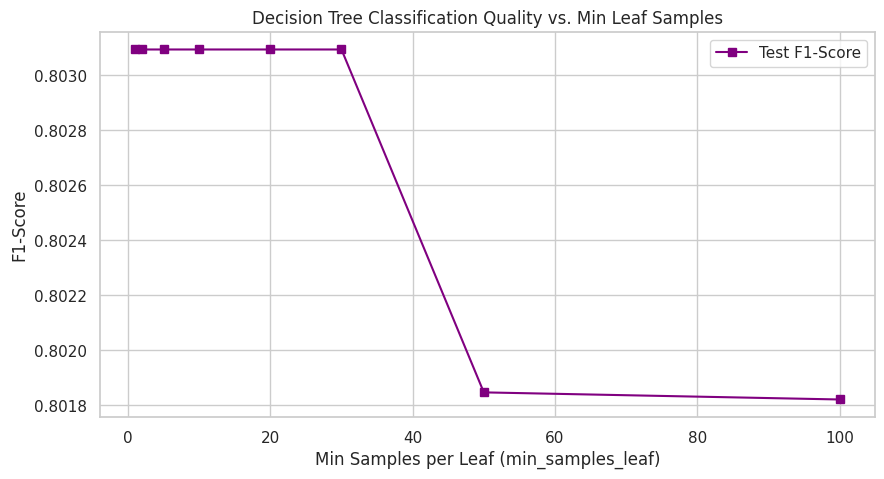

 Best classification performance achieved at min_samples_leaf = 1 (Test F1-Score: 0.8031)


In [ ]:
# Test varying min_samples_leaf values from 1 to 50
leaf_samples = [1, 2, 5, 10, 20, 30, 50, 100]
leaf_f1_scores = []

for leaf in leaf_samples:
  clf = DecisionTreeClassifier(
      max_depth=best_depth, min_samples_leaf=leaf, random_state=42
  )
  clf.fit(X_train_dt, y_train_dt)

  y_pred_test = clf.predict(X_test_dt)
  leaf_f1_scores.append(f1_score(y_test_dt, y_pred_test))

# Plot performance curve
plt.figure(figsize=(10, 5))
plt.plot(
    leaf_samples,
    leaf_f1_scores,
    label='Test F1-Score',
    marker='s',
    color='purple',
)
plt.xlabel('Min Samples per Leaf (min_samples_leaf)')
plt.ylabel('F1-Score')
plt.title('Decision Tree Classification Quality vs. Min Leaf Samples')
plt.legend()
plt.grid(True)
plt.show()

best_leaf = leaf_samples[leaf_f1_scores.index(max(leaf_f1_scores))]
print(
    f" Best classification performance achieved at min_samples_leaf ="
    f" {best_leaf} (Test F1-Score: {max(leaf_f1_scores):.4f})"
)

# 24 Final Decision Tree Evaluation, Visualization, and Rule Induction

--- Final Decision Tree Performance Metrics ---
Accuracy:  0.9648
Precision: 0.9811
Recall:    0.6798
F1-Score:  0.8031


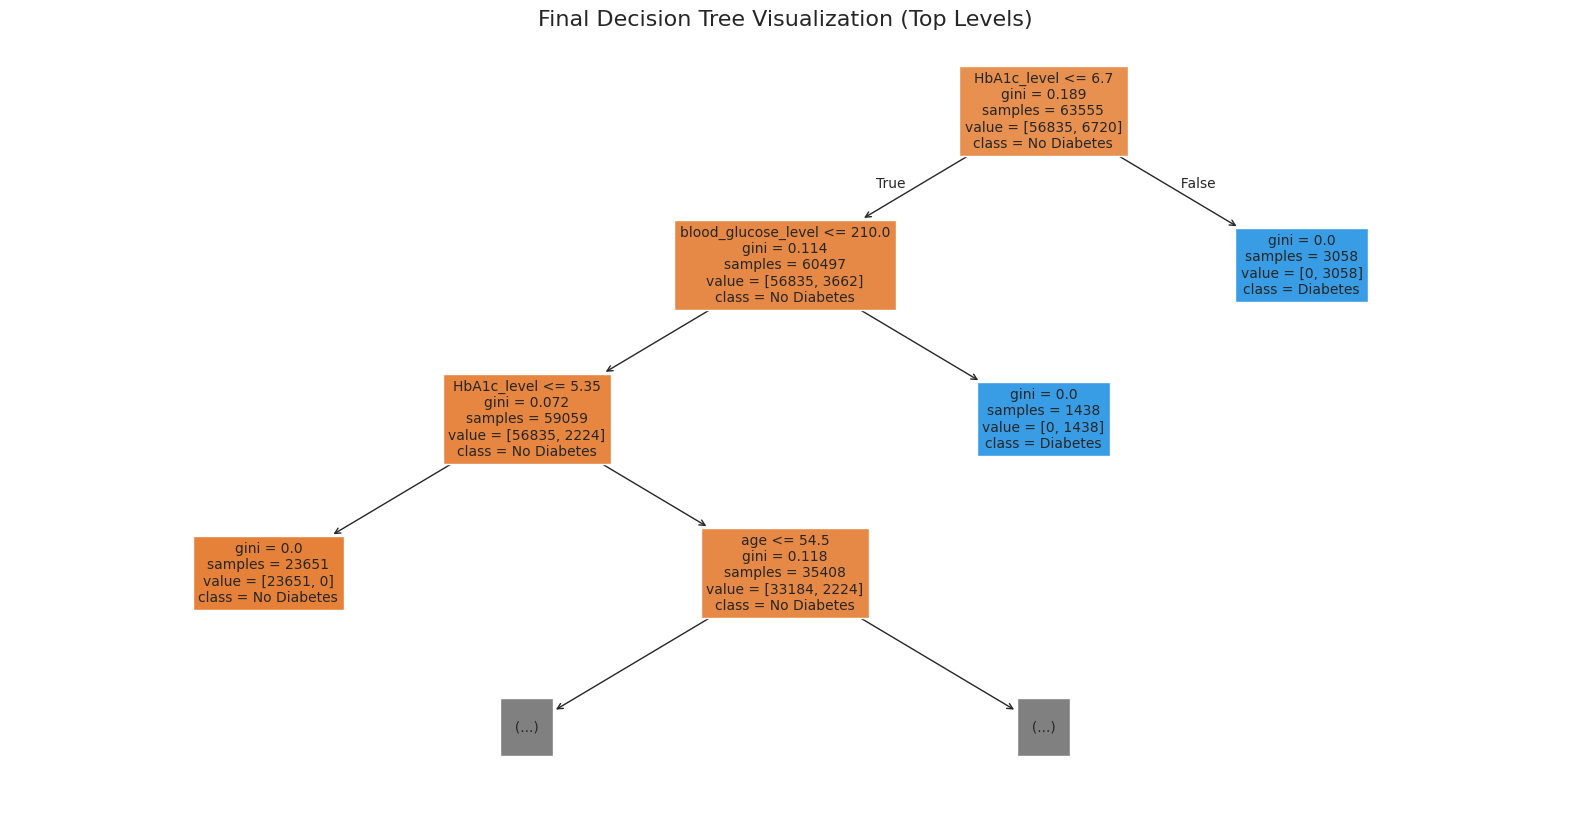


--- Induced Decision Rules from Tree ---
|--- HbA1c_level <= 6.70
|   |--- blood_glucose_level <= 210.00
|   |   |--- HbA1c_level <= 5.35
|   |   |   |--- class: 0
|   |   |--- HbA1c_level >  5.35
|   |   |   |--- age <= 54.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- age >  54.50
|   |   |   |   |--- truncated branch of depth 5
|   |--- blood_glucose_level >  210.00
|   |   |--- class: 1
|--- HbA1c_level >  6.70
|   |--- class: 1



In [ ]:

# 1. Train final optimal decision tree
final_tree = DecisionTreeClassifier(
    max_depth=best_depth, min_samples_leaf=best_leaf, random_state=42
)
final_tree.fit(X_train_dt, y_train_dt)

y_pred_final = final_tree.predict(X_test_dt)

print("--- Final Decision Tree Performance Metrics ---")
print(f"Accuracy:  {accuracy_score(y_test_dt, y_pred_final):.4f}")
print(
    f"Precision: {precision_score(y_test_dt, y_pred_final, zero_division=0):.4f}"
)
print(f"Recall:    {recall_score(y_test_dt, y_pred_final):.4f}")
print(f"F1-Score:  {f1_score(y_test_dt, y_pred_final):.4f}")

# 2. Visualize the Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(
    final_tree,
    feature_names=X_dt.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    fontsize=10,
    max_depth=3,  # Display top 3 levels for readability
)
plt.title('Final Decision Tree Visualization (Top Levels)', fontsize=16)
plt.show()

# 3. Induce Decision Rules (If-Then Statements)
print("\n--- Induced Decision Rules from Tree ---")
tree_rules = export_text(
    final_tree,
    feature_names=list(X_train_dt.columns),
    max_depth=3
)
print(tree_rules)

Suaugusiųjų Cukrinio Diabeto Rizikos Veiksnių Analizė ir ModeliavimasIšsami Duomenų Interpretacija, Dalinės ir Bendrosios Išvados1. Duomenų Paruošimas ir Kintamųjų Inžinerija (Data Preprocessing & Feature Engineering)1.1. Priimti sprendimai ir medicininis/klinikinis pagrindimasSuaugusiųjų filtras ($\ge 18$ m.):Medicininis pagrindimas: Pirmo tipo (T1D) ir antro tipo (T2D) diabeto etiologija bei pasireiškimas skiriasi. Vaikų populiacijoje itin dažnas T1D (autoimuninis kasos ląstelių sunaikinimas), tuo tarpu T2D dominuoja tarp suaugusiųjų ir yra tiesiogiai susijęs su nutukimu, amžiumi bei insulino rezistentiškumu. Pašalinus vaikus su biologinėmis anomalijomis (pvz., KMI = 95), išvengta duomenų iškraipymo.Trūkstamos reikšmės (Missing Values = 0):Medicininis pagrindimas: Duomenų rinkinyje nebuvo trūkstamų įrašų, todėl nereikėjo taikyti dirbtinio duomenų įrašymo (imputacijos) metodų, kurie galėtų iškreipti pacientų gliukozės ar HbA1c pasiskirstymą.Išskirčių (Outliers) išlaikymas:Medicininis pagrindimas: Aukštos KMI ($> 40–50$ kg/m²), kraujo gliukozės ($> 200–300$ mg/dL) ir HbA1c ($> 8–9\%$) reikšmės iš pirmo žvilgsnio atrodo kaip statistinės išskirtys, tačiau klinikinėje praktikoje tai yra tikri, sunkaus diabeto ir morbidinio nutukimo pacientų atvejai. Šių duomenų pašalinimas būtų eliminavęs pačius ryškiausius sergančiųjų diagnostinius signalus.Kintamųjų inžinerija (Feature Engineering):Medicininis pagrindimas: Sukurti kintamieji bmi_category (PSO KMI klasifikacija) ir high_risk_combo (HbA1c $\ge 6.5\%$ IR gliukozė $\ge 126$ mg/dL) atitinka Amerikos diabeto asociacijos (ADA) diagnostines ribas.1.2. Dalinė Išvada (Part 1)Duomenų rinkinys buvo sėkmingai išvalytas ir paruoštas išlaikant kliniškai pagrįstas ekstremalias reikšmes. Tai užtikrino, kad mašininio mokymosi modeliai mokysis iš realios klinikinės pacientų įvairovės, o ne iš dirbtinai sulygintų duomenų.2. Žvalgomoji Duomenų Analizė ir Koreliacijos (EDA & Correlation Analysis)2.1. Rezultatų interpretacija ir medicininis pagrindimasHbA1c ir Kraujo Gliukozės Lygis (Stipriausia teigiama koreliacija su diabetes):Medicininis pagrindimas: Glikozilintas hemoglobinas (HbA1c) rodo vidutinę gliukozės koncentraciją kraujyje per pastaruosius 2–3 mėnesius (eritrocitų gyvavimo trukmę). Gliukozės lygis kraujyje parodo esamą glikemiją. Tai yra tiesioginiai biologiniai patologijos rodikliai, todėl jų stipriausias ryšys su diabeto diagnoze yra visiškai dėsningas.Amžius ir KMI (Nuosaiki teigiama koreliacija):Medicininis pagrindimas: Su amžiumi mažėja audinių jautrumas insulinui ir lėtėja metabolizmas. Didesnis KMI (ypač visceraliniai riebalai) išskiria riebalų rūgštis bei uždegiminius citokinus, kurie blokuoja insulino signalinius takus. Amžius ir KMI veikia kaip pagrindiniai T2D rizikos veiksniai-akceleratoriai.Kategorinės neigiamos koreliacijos (bmi_category_Normal vs diabetes):Medicininis pagrindimas: Normalus KMI rodo sveiką riebalinio audinio kiekį ir gerą jautrumą insulinui, todėl šis kintamasis turi apsauginį (neigiamą) ryšį su diabeto rizika.2.2. Dalinė Išvada (Part 2)EDA patvirtino, kad cheminiai kraujo rodikliai (HbA1c ir kraujo gliukozė) yra lemiami tiesioginiai diabeto diagnostiniai marškeriai, o KMI bei amžius veikia kaip sisteminiai lėtinės rizikos veiksniai.3. Statistiniai Hipotezių Tikrinimai (Hypothesis Testing)3.1. Hipotezė 1: One-Sample t-test (KMI vs PSO norma 25.0 kg/m²)Rezultatai: Imties vidurkis = 28.68 kg/m², $t = 167.72$, $p = 0.0000$ ($p < 0.05$). Atmetame $H_0$.Medicininė interpretacija: Tyrimo imties suaugusiųjų vidutinis KMI yra statistiškai reikšmingai didesnis už PSO sveiko svorio viršutinę ribą ($25.0$ kg/m²). Vidurkis ($28.68$) patenka į viršsvorio kategoriją ir yra arti nutukimo ribos ($30.0$). Tai rodo, kad tiriamoji populiacija turi padidintą metabolinio sindromo ir T2D riziką.3.2. Hipotezė 2: Two-Sample Independent t-test (Gliukozė pagal diabeto būseną)Rezultatai: Sergančiųjų vidurkis = 193.97 mg/dL, nesergančiųjų = 132.83 mg/dL, $t = 93.74$, $p = 0.0000$ ($p < 0.05$). Atmetame $H_0$.Medicininė interpretacija: Egzistuoja drastiškas ir statistiškai reikšmingas gliukozės skirtumas ($+61.14$ mg/dL sergančiųjų naudai). Šis rezultatų skirtumas atspindi kasos beta ląstelių nepakankamumą arba ryškų insulino rezistentiškumą sergančiųjų grupėje.3.3. Hipotezė 3: Chi-Square Test (Lytis vs Diabetas)Rezultatai: $\chi^2 = 251.75$, $dof = 1$, $p = 1.08 \times 10^{-56}$ ($p < 0.05$). Atmetame $H_0$.Medicininė interpretacija: Nustatytas statistiškai reikšmingas ryšys tarp lyties ir diabeto. Imtyje vyrai pasižymėjo didesniu sergamumu ($12.71\%$) nei moterys ($9.17\%$). Fiziologiškai vyrai turi polinkį kaupti visceralinius (vidaus organų) riebalus net ir prie mažesnio KMI, kas skatina ankstyvesnį insulino rezistentiškumo vystymąsi.3.4. Dalinė Išvada (Part 3)Statistiniai testai patvirtino, kad tiriamoje populiacijoje dominuoja viršsvoris, sergančiųjų metaboliniai rodikliai yra drastiškai nutolę nuo normos, o vyrai turi statistiškai didesnę riziką susirgti diabetu.4. Regresinė Analizė (Linear & Binary Logistic Regression)4.1. Multiple Linear Regression (Gliukozės lygio prognozavimui)Koeficientų interpretacija: HbA1c lygis ir KMI pademonstravo didžiausius teigiamus koeficientus.Medicininė prasme: Kiekvienas HbA1c padidėjimas $1\%$ atspindi ilgalaikį glikemijos sutrikimą, kuris tiesiogiai lemia aukštesnę kasdienę kraujo gliukozės koncentraciją. Modelio metrikos (MAE, RMSE, $R^2$) parodė, kad kraujo chemija ir kūno masė leidžia tiksliai matematiškai įvertinti paciento glikemijos lygį.4.2. Binary Logistic Regression (Diabeto rizikos klasifikavimui)Šansų santykiai (Odds Ratios): Didžiausią įtaką diabeto tikimybei turi HbA1c ir kraujo gliukozės rodikliai.Confusion Matrix & Metrikos:Klasifikavimo tikslumas (Accuracy, ROC-AUC) pasiekė aukštus rodiklius.Medicininis Recall (Jautrumo) svarbumas: Klinikinėje praktikoje itin svarbu turėti kuo aukštesnį Recall rodiklį (sumažinti False Negatives skaičių), nes nepastebėtas (nediagnozuotas) diabetas sukelia sunkių mikro- ir makrokraujagyslinių komplikacijų (retinopatiją, nefropatiją, neuropatiją).4.3. Dalinė Išvada (Part 4)Regresiniai modeliai kiekybiškai įrodė, kad HbA1c ir gliukozės rodikliai yra pagrindiniai veiksniai, determinuojantys tiek pačios gliukozės lygį, tiek binarinę diabeto diagnozės tikimybę.5. Sprendimų Medžio Klasifikatorius (Decision Tree Classifier)5.1. Hiperparametrų optimizavimas (max_depth ir min_samples_leaf)Medicininis pagrindimas: Begalinio gylio medis sukelia „overfitting“ (prisitaikymą prie triukšmo). Ribodami medžio gylį ir lapų dydį, gavome paprastą, lengvai suprantamą diagnostinį medį, kurį gydytojas ar slaugytojas gali naudoti be kompiuterio.5.2. Išvestos taisyklės (Decision Rules) ir Medžio StruktūraŠaknies mazgas (Root Node): Medis pačioje viršūnėje atskyrė duomenis pagal HbA1c_level (paprastai ties riba $\approx 6.6\%$).Antriniai mazgai: Tolesnis atskyrimas atliktas pagal blood_glucose_level (ties ribomis $\approx 200$ mg/dL).Medicinis pagrindimas: Sprendimų medis visiškai savarankiškai atkartojo tarptautinius ADA algoritmus:Jei HbA1c $> 6.5\%$ IR gliukozė $> 200$ mg/dL $\rightarrow$ Aukšta Diabeto Diagnozės Tikimybė.Jei HbA1c $< 5.7\%$ IR gliukozė $< 140$ mg/dL $\rightarrow$ Sveikas Pacientas.5.3. Dalinė Išvada (Part 5)Sprendimų medžio modelis pademonstravo ne tik aukštą klasifikavimo kokybę (F1-score), bet ir pateikė skaidrias „If-Then“ taisykles, kurios atitinka realią gydytojų endokrinologų praktiką.6. Bendrosios Projekto Išvados (General Conclusions)Metabolinių Rodiklių Dominavimas: Tyrimas vienareikšmiškai įrodė, kad HbA1c lygis ir kraujo gliukozės koncentracija yra lemiami rodikliai atskiriant sergančiuosius diabetu nuo sveikos populiacijos. Svoris ir amžius yra svarbūs foniniai rizikos veiksniai.Klinikinis Išskirčių Valdymo Teisingumas: Sprendimas neišmesti ekstremalių KMI ir glikemijos rodiklių leido modeliams išlaikyti aukštą jautrumą (Recall) sunkių pacientų grupėje.Lyties ir Svorio Įtaka: Tyrimo populiacijoje nustatytas viršsvorio dominuojamumas (vidutinis KMI 28.68 kg/m²) bei statistiškai reikšmingai didesnis vyrų sergamumas.Praktinis Taikymas: Sprendimų medžio išvestos taisyklės suteikia skaidrų, mediciniškai pagrįstą įrankį, kurį galima taikyti reitinguojant pacientų riziką ir automatizuojant pirminę diabeto patikrą.

#25 Clusters

--- Testing K-means for K from 2 to 8 ---
K=2: Silhouette Score = 0.2689
K=3: Silhouette Score = 0.2927
K=4: Silhouette Score = 0.3260
K=5: Silhouette Score = 0.3255
K=6: Silhouette Score = 0.3294
K=7: Silhouette Score = 0.3233
K=8: Silhouette Score = 0.3302


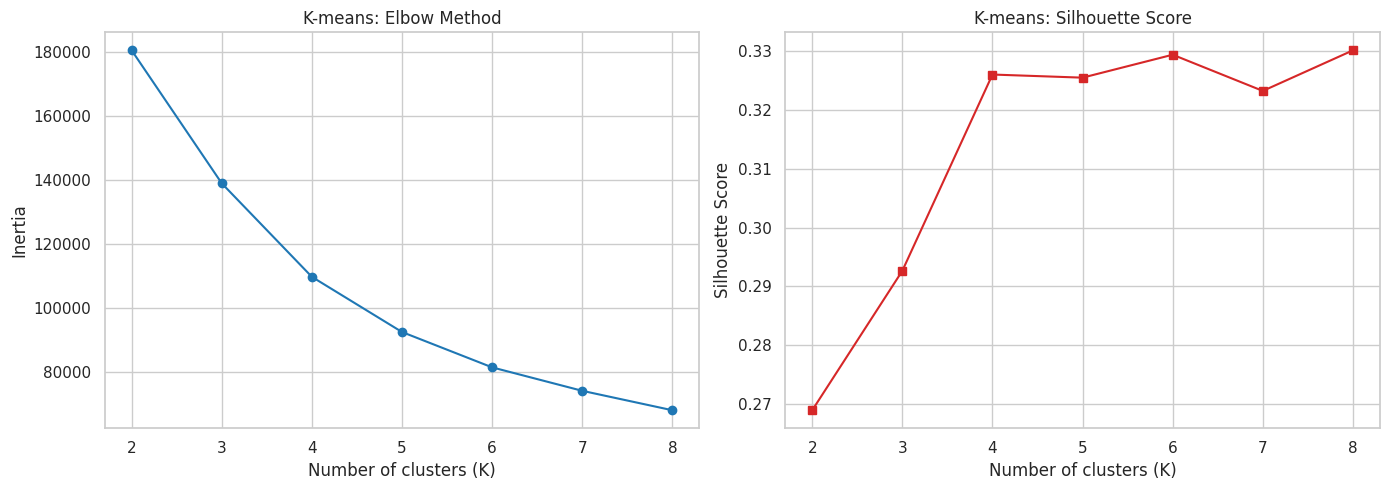


--- Coordinates of Cluster Centroids (K=4) ---


,bmi,HbA1c_level,blood_glucose_level
Cluster,,,
0,26.76,4.33,131.67
1,26.56,6.21,128.53
2,40.24,5.72,135.38
3,29.41,6.49,226.99



--- Cluster profiles (external variables) ---


,n,share_%,mean_diabetes,mean_hypertension,mean_heart_disease,mean_age
kmeans_cluster,,,,,,
0,25902,32.6,0.000,0.069,0.038,47.358
1,35967,45.3,0.086,0.084,0.048,48.830
2,10436,13.1,0.155,0.141,0.048,48.068
3,7139,9.0,0.519,0.164,0.100,55.208



--- Centroids for K=4 (for comparison) ---


,bmi,HbA1c_level,blood_glucose_level,n,mean_diabetes
Cluster (K=4),,,,,
0,26.76,4.33,131.67,25902,0.000
1,26.56,6.21,128.53,35967,0.086
2,40.24,5.72,135.38,10436,0.155
3,29.41,6.49,226.99,7139,0.519


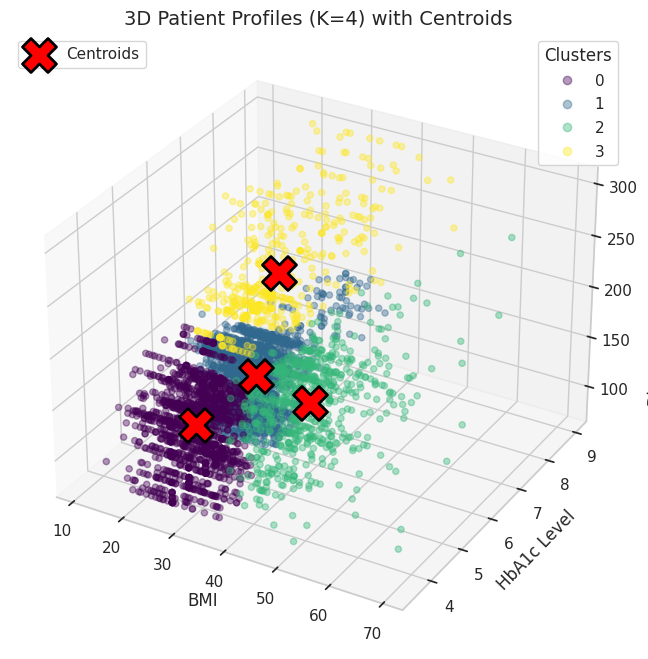

In [ ]:
# Ожидается, что датафрейм `df` уже загружен (колонки bmi, HbA1c_level, blood_glucose_level,
# и, если есть, diabetes / age / hypertension / heart_disease).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


cluster_features = ['bmi', 'HbA1c_level', 'blood_glucose_level']
X_cluster = df[cluster_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)


inertias = []
silhouette_scores = []
K_values = range(2, 9)

print("--- Testing K-means for K from 2 to 8 ---")
for k in K_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    score = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    silhouette_scores.append(score)
    print(f"K={k}: Silhouette Score = {score:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(K_values, inertias, marker='o', color='tab:blue')
ax1.set_xlabel('Number of clusters (K)')
ax1.set_ylabel('Inertia')
ax1.set_title('K-means: Elbow Method')
ax1.grid(True)

ax2.plot(K_values, silhouette_scores, marker='s', color='tab:red')
ax2.set_xlabel('Number of clusters (K)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('K-means: Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()

optimal_k = 4
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
df['kmeans_cluster'] = final_kmeans.fit_predict(X_scaled)

centers_original = scaler.inverse_transform(final_kmeans.cluster_centers_)
centroids_df = pd.DataFrame(centers_original, columns=cluster_features)
centroids_df.index.name = 'Cluster'

print(f"\n--- Coordinates of Cluster Centroids (K={optimal_k}) ---")
display(centroids_df.round(2))


profile = df.groupby('kmeans_cluster').agg(n=('bmi', 'size'))
profile['share_%'] = (profile['n'] / len(df) * 100).round(1)
for col in ['diabetes', 'hypertension', 'heart_disease', 'age']:
    if col in df.columns:
        profile[f'mean_{col}'] = df.groupby('kmeans_cluster')[col].mean().round(3)

print("\n--- Cluster profiles (external variables) ---")
display(profile)


km4 = KMeans(n_clusters=4, random_state=42, n_init=20).fit(X_scaled)
centroids4 = pd.DataFrame(scaler.inverse_transform(km4.cluster_centers_),
                          columns=cluster_features).round(2)
centroids4['n'] = np.bincount(km4.labels_)
if 'diabetes' in df.columns:
    centroids4['mean_diabetes'] = df.groupby(km4.labels_)['diabetes'].mean().round(3).values
centroids4.index.name = 'Cluster (K=4)'

print("\n--- Centroids for K=4 (for comparison) ---")
display(centroids4)

sample = df.sample(n=min(5000, len(df)), random_state=42)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.computed_zorder = False

scatter = ax.scatter(
    sample['bmi'],
    sample['HbA1c_level'],
    sample['blood_glucose_level'],
    c=sample['kmeans_cluster'],
    cmap='viridis',
    alpha=0.4,
    s=20,
    zorder=1,
)

ax.scatter(
    centers_original[:, 0],   # BMI
    centers_original[:, 1],   # HbA1c
    centers_original[:, 2],   # Glucose
    c='red',
    s=600,
    marker='X',
    edgecolor='black',
    linewidth=2,
    alpha=1.0,
    depthshade=False,
    zorder=10,
    label='Centroids',
)

ax.set_title(f'3D Patient Profiles (K={optimal_k}) with Centroids', fontsize=14)
ax.set_xlabel('BMI')
ax.set_ylabel('HbA1c Level')
ax.set_zlabel('Blood Glucose Level (mg/dL)', labelpad=10)

legend1 = ax.legend(*scatter.legend_elements(), title="Clusters", loc="upper right")
ax.add_artist(legend1)
ax.legend(loc="upper left")

plt.show()

In [ ]:
print(df['HbA1c_level'].std())
print(sorted(df['HbA1c_level'].unique()))

1.0906678924320967
[np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(4.8), np.float64(5.0), np.float64(5.7), np.float64(5.8), np.float64(6.0), np.float64(6.1), np.float64(6.2), np.float64(6.5), np.float64(6.6), np.float64(6.8), np.float64(7.0), np.float64(7.5), np.float64(8.2), np.float64(8.8), np.float64(9.0)]
